# Sesion 05-bi-ago-2026

In [2]:
url = "https://raw.githubusercontent.com/edavgaun/RCEL_506/refs/heads/main/Module%203/Housing%20states/housing_wa.csv"

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# y: precio
data = pd.read_csv(url)
data.shape

(7061, 21)

In [5]:
# x: zona, tamaño, antiguedad, estado del inmuele, amenidades
data.columns


Index(['Unnamed: 0', 'url', 'region', 'price', 'type', 'sqfeet', 'beds',
       'baths', 'cats_allowed', 'dogs_allowed', 'smoking_allowed',
       'wheelchair_access', 'electric_vehicle_charge', 'comes_furnished',
       'laundry_options', 'parking_options', 'image_url', 'description', 'lat',
       'long', 'state'],
      dtype='object')

In [6]:
cols2remove = ["Unnamed: 0", "url", "image_url", "state"]
data.drop(columns=cols2remove, inplace=True)
data


,region,price,type,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,electric_vehicle_charge,comes_furnished,laundry_options,parking_options,description,lat,long
0,bellingham,2200,house,1486,3,2.0,0,0,1,0,0,0,w/d in unit,detached garage,3 bedroom 2 bath newly renovated home in North...,48.7490,-122.489
1,bellingham,1250,apartment,950,2,1.0,0,0,1,0,0,0,laundry on site,off-street parking,*Two bedroom with one bath *950 square feet ...,48.7828,-122.526
2,bellingham,1282,apartment,1356,4,2.0,1,1,0,1,0,0,w/d in unit,carport,Our units are now available on a first come fi...,48.8094,-122.502
3,bellingham,1250,apartment,980,2,1.5,1,0,0,0,0,0,w/d in unit,carport,Contact info: show contact info HUGE SAVI...,48.7850,-122.523
4,bellingham,1550,house,945,2,1.0,0,0,1,0,0,0,laundry in bldg,street parking,OMNI Property Management 510 E. Maple Rent: $1...,48.7450,-122.478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7056,yakima,1146,apartment,782,2,1.0,1,1,0,0,0,0,laundry on site,off-street parking,University Park & Place \t ...,47.0139,-120.545
7057,yakima,1086,apartment,720,2,1.0,1,1,0,0,0,0,laundry on site,off-street parking,University Park & Place \t ...,47.0103,-120.542
7058,yakima,1196,apartment,782,2,1.0,1,1,0,0,0,0,laundry on site,off-street parking,University Park & Place \t ...,47.0139,-120.545
7059,yakima,1075,townhouse,960,2,1.5,1,1,0,0,0,0,w/d in unit,off-street parking,Greenpointe Townhomes\t ...,47.0106,-120.539


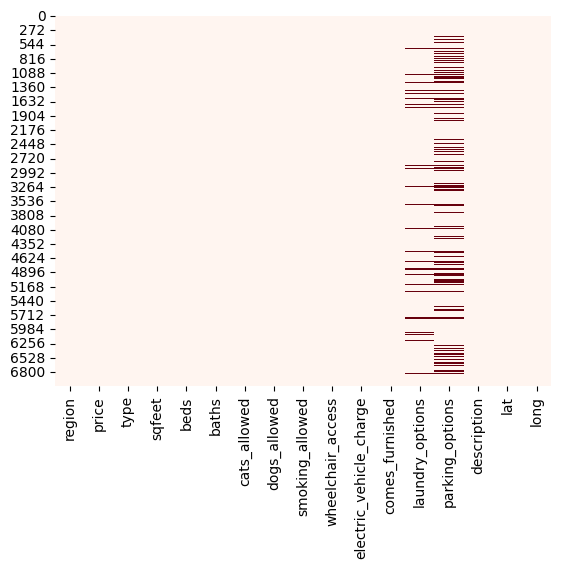

In [7]:
sns.heatmap(data.isna(), cbar=False, cmap="Reds")
plt.show()

In [8]:
data.drop(columns=["parking_options"], inplace=True)
data.dropna(inplace=True)
data.reset_index(drop=True, inplace=True)
data.shape

(6433, 16)

# Exploratory Data Analysis (EDA)
Necesario para proyecto

In [9]:
data.describe().round(2)

,price,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,electric_vehicle_charge,comes_furnished,lat,long
count,6433.00,6433.00,6433.00,6433.00,6433.00,6433.0,6433.00,6433.00,6433.00,6433.00,6433.00,6433.00
mean,1563.81,977.19,1.90,1.45,0.82,0.8,0.39,0.16,0.04,0.07,46.99,-120.62
std,3273.43,544.79,0.96,0.58,0.38,0.4,0.49,0.37,0.18,0.25,1.79,3.06
min,0.00,30.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,32.69,-134.53
25%,1100.00,708.00,1.00,1.00,1.00,1.0,0.00,0.00,0.00,0.00,46.27,-122.31
50%,1375.00,935.00,2.00,1.00,1.00,1.0,0.00,0.00,0.00,0.00,47.29,-121.80
75%,1750.00,1100.00,2.00,2.00,1.00,1.0,1.00,0.00,0.00,0.00,47.65,-119.27
max,250000.00,27700.00,7.00,6.00,1.00,1.0,1.00,1.00,1.00,1.00,58.36,-77.02


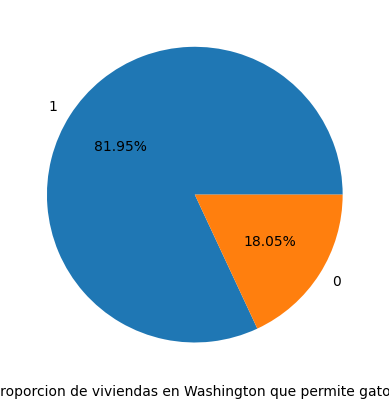

In [10]:
data.cats_allowed.value_counts().plot(kind="pie", autopct="%.2f%%")
plt.ylabel("")
plt.xlabel("Proporcion de viviendas en Washington que permite gatos")
plt.show()


In [11]:
!pip install fg-data-profiling

In [12]:
from data_profiling import ProfileReport

In [13]:
profile = ProfileReport(data, title="Mi primer Reporte")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:02<00:00,  7.72it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

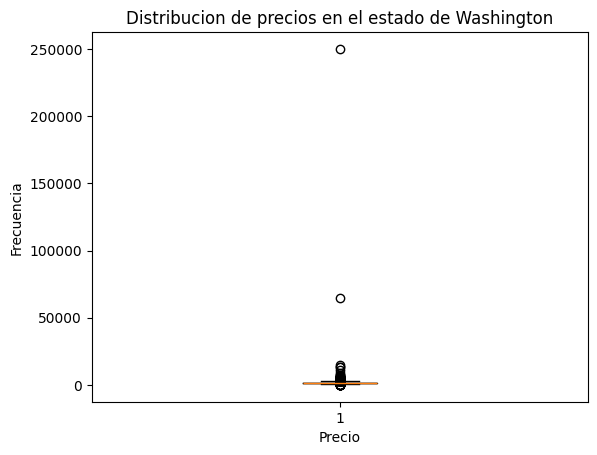

In [14]:
plt.boxplot(x=data.price)
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.title("Distribucion de precios en el estado de Washington")
plt.show()

In [15]:
data=data[(data.price>700) & (data.price < 6500)]
data.reset_index(drop=True, inplace=True)
data.shape

(6312, 16)

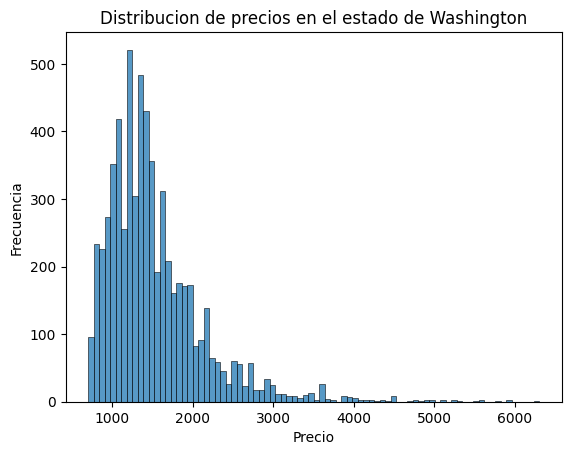

In [16]:
sns.histplot(data=data, x="price")
plt.xlabel("Precio")
plt.ylabel("Frecuencia")
plt.title("Distribucion de precios en el estado de Washington")
plt.show()

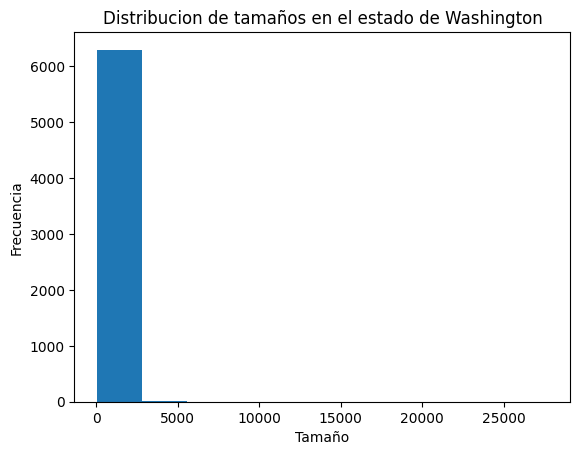

In [17]:
plt.hist(data=data, x="sqfeet")
plt.xlabel("Tamaño")
plt.ylabel("Frecuencia")
plt.title("Distribucion de tamaños en el estado de Washington")
plt.show()

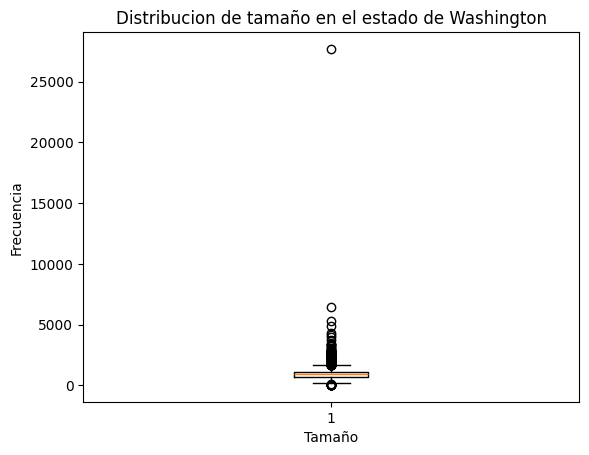

In [18]:
plt.boxplot(data=data, x="sqfeet")
plt.xlabel("Tamaño")
plt.ylabel("Frecuencia")
plt.title("Distribucion de tamaño en el estado de Washington")
plt.show()

In [19]:
data=data[(data.sqfeet>700) & (data.sqfeet < 3000)]
data.reset_index(drop=True, inplace=True)
data.shape


(4788, 16)

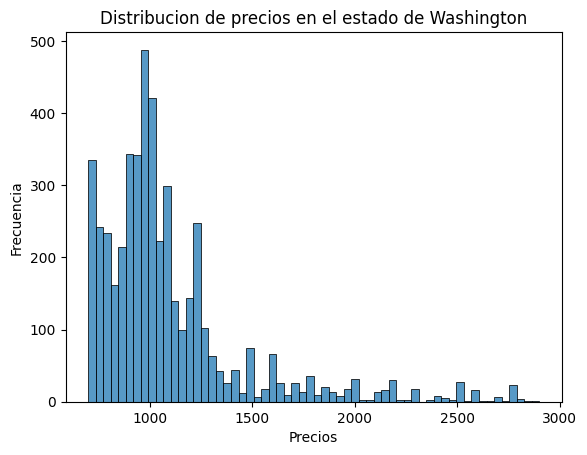

In [20]:
sns.histplot(data=data, x="sqfeet")
plt.xlabel("Precios")
plt.ylabel("Frecuencia")
plt.title("Distribucion de precios en el estado de Washington")
plt.show()


In [21]:
data.columns

Index(['region', 'price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'laundry_options',
       'description', 'lat', 'long'],
      dtype='object')

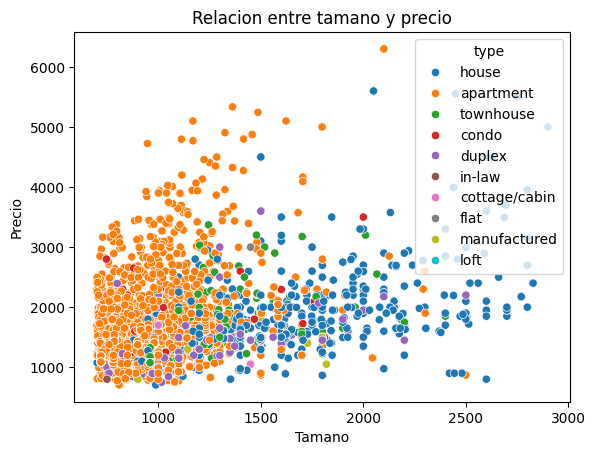

In [22]:
sns.scatterplot(data=data, x="sqfeet", y="price", hue="type")
plt.xlabel("Tamano")
plt.ylabel("Precio")
plt.title("Relacion entre tamano y precio")
plt.show()


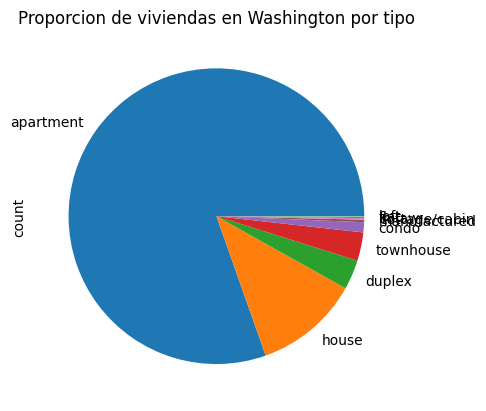

type
apartment        0.80
house            0.11
duplex           0.03
townhouse        0.03
condo            0.01
manufactured     0.00
cottage/cabin    0.00
in-law           0.00
flat             0.00
loft             0.00
Name: proportion, dtype: float64


In [23]:
data["type"].value_counts().plot(kind="pie")
plt.title("Proporcion de viviendas en Washington por tipo")
plt.show()
print(data["type"].value_counts(normalize=True).round(2))

In [24]:
propiedades = ["apartment", "house", "duplex", "townhouse"]
data["type2"] = data["type"].apply(lambda x: x if x in propiedades else "other")

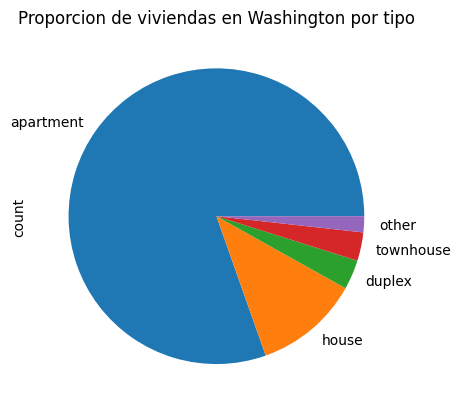

type2
apartment    0.80
house        0.11
duplex       0.03
townhouse    0.03
other        0.02
Name: proportion, dtype: float64


In [25]:
data["type2"].value_counts().plot(kind="pie")
plt.title("Proporcion de viviendas en Washington por tipo")
plt.show()
print(data["type2"].value_counts(normalize=True).round(2))


color: cuantitativo, discreto
tamano: cuantitativo, continuo

<img src='https://micelia.net/wp-content/uploads/2025/10/variables-Bertin-2-1024x683.webp' width=500>


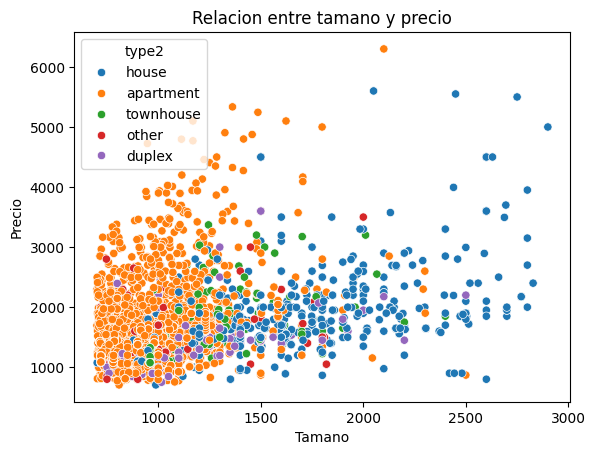

In [26]:
sns.scatterplot(data=data, x="sqfeet", y="price", 
                #style=type2
                #size="sqfeet",
                hue="type2"
                )
plt.xlabel("Tamano")
plt.ylabel("Precio")
plt.title("Relacion entre tamano y precio")
plt.show()


In [27]:
url_wa = "https://github.com/edavgaun/topojson/raw/refs/heads/master/countries/us-states/WA-53-washington-counties.json"


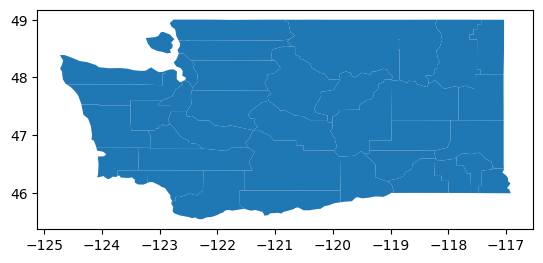

In [28]:
import geopandas as gpd

mapa = gpd.read_file(url_wa)
mapa.plot()
plt.show()

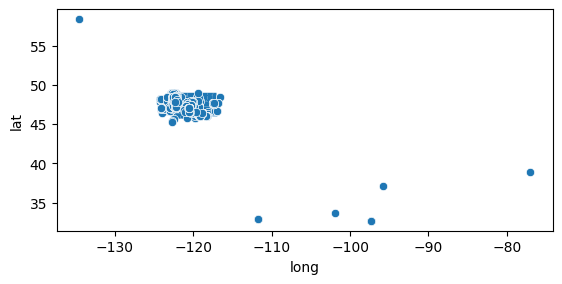

In [29]:
fig, axs = plt.subplots()
mapa.plot(ax=axs)
sns.scatterplot(data=data, x="long", y="lat", ax=axs)
plt.show()


In [30]:
data = data[(data.lat > 40) & (data.lat < 50)]
data = data[(data.long > -130) & (data.long < -115)]
data.reset_index(drop=True, inplace=True)
data.shape


(4707, 17)

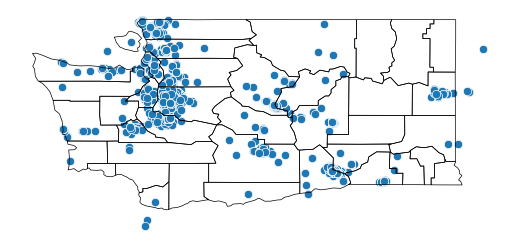

In [31]:
fig, axs = plt.subplots()
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs)
sns.scatterplot(data=data, x="long", y="lat", ax=axs)
plt.axis("off")
plt.show()


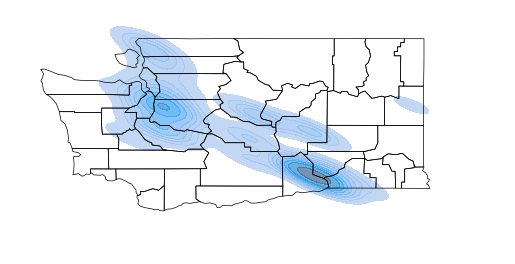

In [32]:
fig, axs = plt.subplots()
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs
                    )
sns.kdeplot(data=data, x="long", y="lat", ax=axs,
            fill=True, alpha=0.7
            )
plt.axis("off")
plt.show()


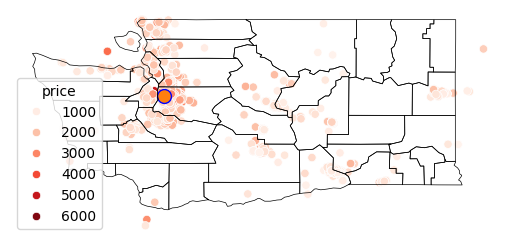

In [33]:
seattle_lat = 47.6062
seattle_long = -122.3321


fig, axs = plt.subplots()
mapa.boundary.plot(color="black", linewidth=0.5, ax=axs)
sns.scatterplot(data=data, x="long", y="lat", ax=axs,
                hue="price", palette="Reds"
                )
plt.scatter(seattle_long, seattle_lat, color=None, s=100, edgecolor="Blue")
plt.axis("off")
plt.show()

# Machine Learning, sesion 5, 2026-09-07

- unsupervised: clustering, dimensionality reduction
- supervised: classification, prediction (regression)

---

<img src='https://www.researchgate.net/profile/Anh-Nguyen-498/publication/314202159/figure/fig1/AS:759631093710848@1558121574081/A-flowchart-of-a-supervised-machine-learning-model_W640.jpg' width=600>


---

data fallacies:
- cherry picking, data dredging, survivorship bias, cobra effect, falsa causality, gerrymandering


6 pasos


In [34]:
# 1. seleccionar modelo (vamos a utilizar regresión lineal múltiple)
from sklearn.linear_model import LinearRegression


In [35]:
# 2. Crear un modelo a partir de la biblioteca (Instancia)
model_s = LinearRegression()


In [36]:
# 3. Seleccion de datos (Xs, Y)
X = ["sqfeet"]
y = "price"


In [37]:
# 4. entrenar al modelo (fit)
model_s.fit(data[X], data[y])


LinearRegression()

In [38]:
# 5. métricas del modelo
model_s.score(data[X], data[y])


0.12497492730991366

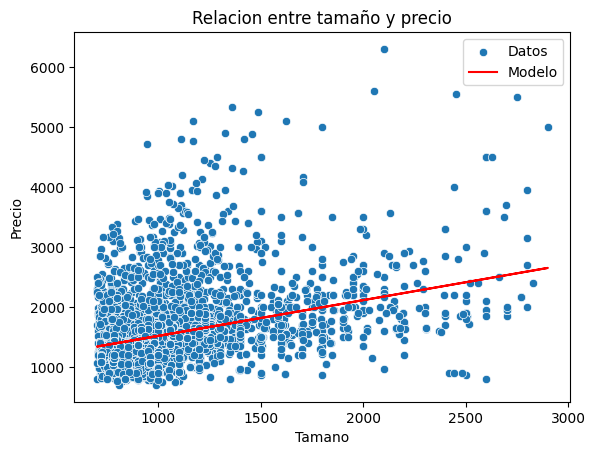

In [39]:
y_pred = model_s.predict(data[X])

sns.scatterplot(data=data, x="sqfeet", y="price")
plt.plot(data[X], y_pred, color="red")
plt.xlabel("Tamano")
plt.ylabel("Precio")
plt.legend(["Datos", "Modelo"])
plt.title("Relacion entre tamaño y precio")
plt.show()


Evaluacion del modelo

**Interpretacion de $R^2$**

- Buen resultado: 1 - 0.75
- Resultado Medio: 0.75 - 0.5
- Resultado Bajo: 0.5 - 0.25
- Resultado Nulo: 0.25 - 0


In [40]:
data.columns

Index(['region', 'price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'laundry_options',
       'description', 'lat', 'long', 'type2'],
      dtype='object')

In [41]:
data['type2'].unique()

array(['house', 'apartment', 'townhouse', 'other', 'duplex'], dtype=object)

In [42]:
# One Hot Encoding
data = pd.get_dummies(data, columns=["type2"])
data.columns


Index(['region', 'price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'laundry_options',
       'description', 'lat', 'long', 'type2_apartment', 'type2_duplex',
       'type2_house', 'type2_other', 'type2_townhouse'],
      dtype='object')

In [43]:
# creando un modelo de regresion lineal multiple
model_s = LinearRegression()
X = ["sqfeet", 'beds', 'type2_apartment', 'type2_duplex',
    'type2_house', 'type2_townhouse', 'type2_other', 'lat', 'long']
y = "price"
model_s.fit(data[X], data[y])
model_s.score(data[X], data[y])



0.3256935384007298

In [44]:
# creando un modelo de regresion lineal multiple
# con todos los descriptores numericos
model_s = LinearRegression()
X = ['sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished',
       'lat', 'long', 'type2_apartment', 'type2_duplex',
       'type2_house', 'type2_other', 'type2_townhouse']
y = "price"
model_s.fit(data[X], data[y])
model_s.score(data[X], data[y])


0.46886002009214833

In [45]:
data.columns

Index(['region', 'price', 'type', 'sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished', 'laundry_options',
       'description', 'lat', 'long', 'type2_apartment', 'type2_duplex',
       'type2_house', 'type2_other', 'type2_townhouse'],
      dtype='object')

In [46]:
data.description[0]
# "... newly renovated home ..."
# "...   Refrigerator, dishwasher, stove, microwave, washer and dryer included in the unit. ..."


'3 bedroom 2 bath newly renovated home in North Bellingham with a yard and detached garage.   Refrigerator, dishwasher, stove, microwave, washer and dryer included in the unit.  No pets, no drugs or smoking. Must have excellent rental history.  We will be collecting first months rent as well as a damage deposit of $2200.   Tenant pay all utilities/electric/garbage.  Please inquire for more information'

## Bag of Words (BoW)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import re

# Define a cleaning function
def clean_text(text):
    # Remove words with numbers or special characters, and words shorter than 4 characters
    words = re.findall(r'\b[a-zA-Z]{4,}\b', text.lower())
    return ' '.join(words)
# Apply the cleaning function to the 'description' column
data['cleaned_description'] = data['description'].apply(clean_text)
# Initialize CountVectorizer
vectorizer = CountVectorizer()
# Fit and transform the cleaned 'description' column to create the BoW model
bow_matrix = vectorizer.fit_transform(data['cleaned_description'])
# Display the shape of the resulting BoW matrix
print(f"Shape of Bag-of-Words matrix: {bow_matrix.shape}")
# Display some of the feature names (words) learned by the vectorizer
print("First 20 feature names (after cleaning):")
print(vectorizer.get_feature_names_out()[:20])

Shape of Bag-of-Words matrix: (4707, 9676)
First 20 feature names (after cleaning):
['aaron' 'aberdeen' 'abierto' 'ability' 'abla' 'able' 'aboard' 'abode'
 'aboretum' 'abound' 'abounds' 'about' 'above' 'absolutely' 'abundance'
 'abundant' 'abuse' 'abuts' 'academic' 'academy']


In [50]:
new_cols = ["community", "center", "amenities", "pool", "fitness"]


In [51]:
for col in new_cols:
    data[col] = data.description.apply(lambda x: 1 if col in x else 0)
    

In [52]:
data

,region,price,type,sqfeet,beds,baths,cats_allowed,dogs_allowed,smoking_allowed,wheelchair_access,...,type2_duplex,type2_house,type2_other,type2_townhouse,cleaned_description,community,center,amenities,pool,fitness
0,bellingham,2200,house,1486,3,2.0,0,0,1,0,...,False,True,False,False,bedroom bath newly renovated home north bellin...,0,0,0,0,0
1,bellingham,1250,apartment,950,2,1.0,0,0,1,0,...,False,False,False,False,bedroom with bath square feet water sewer gara...,0,0,0,0,0
2,bellingham,1282,apartment,1356,4,2.0,1,1,0,1,...,False,False,False,False,units available first come first serve basis r...,1,1,1,0,0
3,bellingham,1250,apartment,980,2,1.5,1,0,0,0,...,False,False,False,False,contact info show contact info huge savings ca...,1,0,0,1,0
4,bellingham,1550,house,945,2,1.0,0,0,1,0,...,False,True,False,False,omni property management maple rent security d...,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4702,yakima,1146,apartment,782,2,1.0,1,1,0,0,...,False,False,False,False,university park place property address ellensb...,1,0,0,0,0
4703,yakima,1086,apartment,720,2,1.0,1,1,0,0,...,False,False,False,False,university park place property address ellensb...,0,0,0,0,0
4704,yakima,1196,apartment,782,2,1.0,1,1,0,0,...,False,False,False,False,university park place property address ellensb...,1,0,1,0,0
4705,yakima,1075,townhouse,960,2,1.5,1,1,0,0,...,False,False,False,True,greenpointe townhomes property address suite e...,1,0,1,0,0


In [53]:
model_m = LinearRegression()
X = ['sqfeet', 'beds', 'baths', 'cats_allowed',
       'dogs_allowed', 'smoking_allowed', 'wheelchair_access',
       'electric_vehicle_charge', 'comes_furnished',
       'lat', 'long', 'type2_apartment', 'type2_duplex',
       'type2_house', 'type2_other', 'type2_townhouse'] + new_cols

y = "price"
model_m.fit(data[X], data[y])
model_m.score(data[X], data[y])


0.5055016807239177

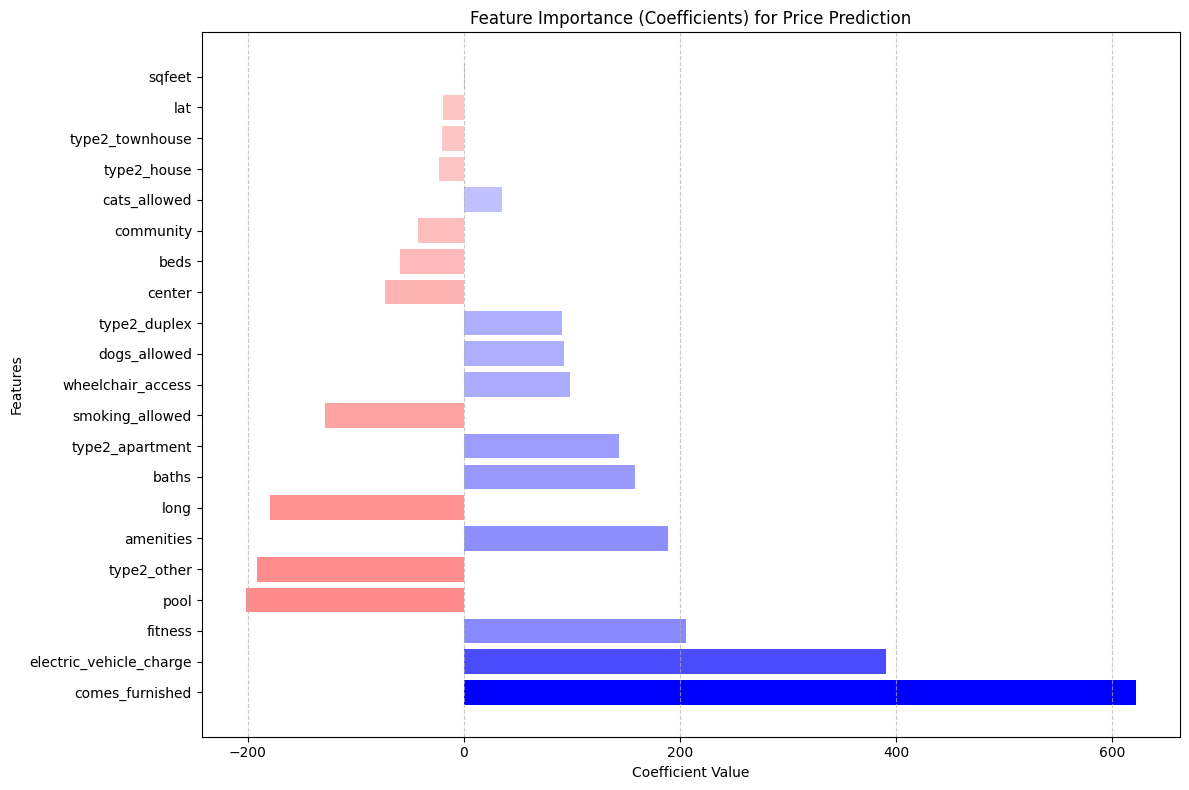

In [54]:
# Feature importance plot
# Get coefficients and feature names
coefficients = model_m.coef_
features = X
# Create a DataFrame for better handling and plotting
feature_importance = pd.DataFrame({'Feature': features, 'Coefficient': coefficients})
# Sort by absolute coefficient value for better visualization
feature_importance['Abs_Coefficient'] = feature_importance['Coefficient'].abs()
feature_importance = feature_importance.sort_values(by='Abs_Coefficient', ascending=False)
# Normalize absolute coefficients for alpha values (0.2 to 1.0)
min_abs_coef = feature_importance['Abs_Coefficient'].min()
max_abs_coef = feature_importance['Abs_Coefficient'].max()
# Avoid division by zero if all coefficients are the same or zero
if max_abs_coef == min_abs_coef or max_abs_coef == 0:
    feature_importance['Alpha'] = 1.0
else:
    feature_importance['Alpha'] = 0.2 + 0.8 * ((feature_importance['Abs_Coefficient'] - min_abs_coef) / (max_abs_coef - min_abs_coef))
# Create a 'Color' column based on the sign of the Coefficient
feature_importance['Color'] = feature_importance['Coefficient'].apply(lambda x: 'blue' if x >= 0 else 'red')
# Create the plot using plt.barh for individual alpha control
plt.figure(figsize=(12, 8))
# Plot each bar individually
for i, row in feature_importance.iterrows():
    plt.barh(y=row['Feature'], width=row['Coefficient'], color=row['Color'], alpha=row['Alpha'])
plt.title('Feature Importance (Coefficients) for Price Prediction')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# repetir ejercicio con otro estado, mostrar en comentarios 
# la razon de seleccion de varaiables, graficas, metodos

